# MEIKURAL Version 1 — raw audio inference

Run from the repository root or `notebooks/`, using the project virtual environment. Install dependencies and train a checkpoint first; see `README.md` and `docs/ver1.tex`.

Input is **audio only**, of any positive duration. Each window gets its own estimated tonic and tonic-aligned STFT. The model ranks seven supported raags; scores are comparative, not calibrated probabilities. Popular songs may mix raags or be outside these classes. Overlapping windows are correlated.

This notebook contains no training or feature-extraction implementation; it imports the same pipeline used by the commands.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "src/ver1/config.json").is_file(), "Launch from the repository root or notebooks/"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.ver1.config import load_config, resolve_path
from src.ver1.inference.predict import predict

config = load_config()


## Choose the audio and checkpoint

Edit these two paths. Relative audio paths are relative to the repository. The checkpoint supplies its own saved preprocessing and model settings; current config edits cannot alter the trained representation.

In [22]:
AUDIO_PATH = "/home/mushu-cislab/GitHub/MEIKURAL/data/test_ver1_handpicked/jog/Venkatesh_kumar.mp3"
CHECKPOINT_PATH = resolve_path(config["paths"]["run"]) / "latest.pt"


In [23]:
result = predict(AUDIO_PATH, CHECKPOINT_PATH)
print(result["message"])
print(f"Duration: {result['duration_seconds']:.3f} s | Device: {result['device']}")
print(f"Usable windows: {result['usable_windows']} | Failed windows: {result['failed_windows']}")


Comparative seven-class scores, not calibrated probabilities.
Duration: 1124.844 s | Device: cuda
Usable windows: 75 | Failed windows: 0


In [24]:
import pandas as pd
from IPython.display import display

print("Overall ranking (real-duration-weighted window scores)")
display(pd.DataFrame(result["ranking"]))
columns = ["start_seconds", "valid_start_seconds", "valid_seconds", "left_padding_seconds",
           "right_padding_seconds", "tonic_hz", "top_raag", "failure"]
display(pd.DataFrame(result["windows"])[columns])


Overall ranking (real-duration-weighted window scores)


,raag,score
0,Todi,0.525312
1,Jog,0.243489
2,Miyan Malhar,0.105263
3,Bhairavi,0.083747
4,Lalit,0.027985
5,Marwa,0.008021
6,Shree,0.006182


,start_seconds,valid_start_seconds,valid_seconds,left_padding_seconds,right_padding_seconds,tonic_hz,top_raag,failure
0,-15.0,0.0,15.000000,15.0,0.000000,313.843719,Marwa,None
1,0.0,0.0,30.000000,0.0,0.000000,235.003204,Jog,None
2,15.0,15.0,30.000000,0.0,0.000000,313.843719,Jog,None
3,30.0,30.0,30.000000,0.0,0.000000,195.282974,Jog,None
4,45.0,45.0,30.000000,0.0,0.000000,155.835159,Lalit,None
...,...,...,...,...,...,...,...,...
70,1035.0,1035.0,30.000000,0.0,0.000000,81.987076,Todi,None
71,1050.0,1050.0,30.000000,0.0,0.000000,81.987076,Todi,None
72,1065.0,1065.0,30.000000,0.0,0.000000,81.987076,Todi,None
73,1080.0,1080.0,30.000000,0.0,0.000000,81.987076,Miyan Malhar,None


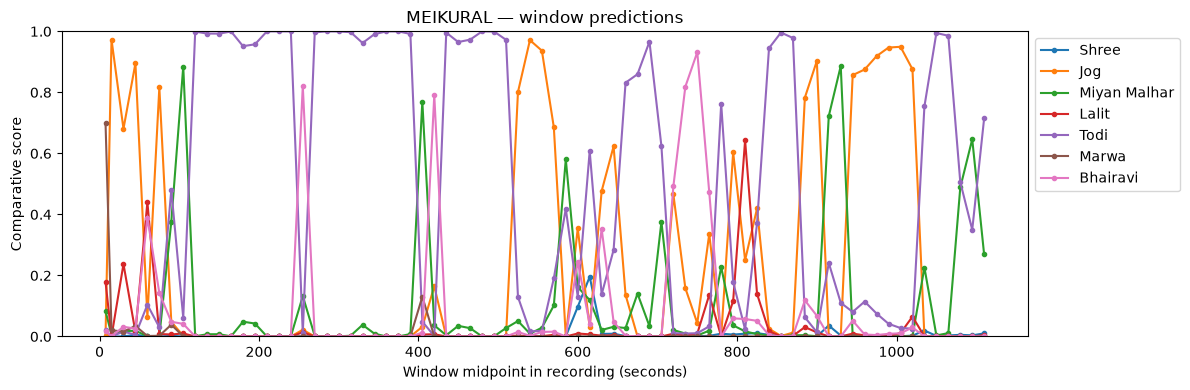

In [25]:
import matplotlib.pyplot as plt
import numpy as np

successful = [row for row in result["windows"] if row["scores"] is not None]
if successful:
    times = [row["valid_start_seconds"] + row["valid_seconds"] / 2 for row in successful]
    scores = np.asarray([row["scores"] for row in successful])
    fig, ax = plt.subplots(figsize=(12, 4))
    for index, label in enumerate(result["classes"]):
        ax.plot(times, scores[:, index], marker=".", label=label)
    ax.set(xlabel="Window midpoint in recording (seconds)", ylabel="Comparative score",
           ylim=(0, 1), title="MEIKURAL — window predictions")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    fig.tight_layout()
    plt.show()
else:
    print("No score timeline: inspect window failures above.")


## Interpretation

The overall ranking averages successful windows, weighted by their real duration. It reduces the contribution of padded windows but does not make overlapping windows independent. A changing raag or key within a song can make the whole-recording average misleading; inspect the timeline.

No unknown-raag rejection is implemented. Tonic estimates can be wrong even when extraction succeeds. Very short clips and speech are especially unreliable. A decode error stops inference rather than returning a result from a truncated file. No external evaluation has been performed yet.